# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
from aitlas.datasets import Sentinel2CloudCoverSegmentationDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose
import numpy as np

## Visualize images and masks

New train/val/test split

In [ ]:
# rgb images
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/Sentinel-2_cloud_cover_segmentation/",
    "csv_file": "/home/dragik/data/FAIR_EO/Sentinel-2_cloud_cover_segmentation/sentinel_2_cloud_cover_segmentation_train.csv"
}
dataset = Sentinel2CloudCoverSegmentationDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 12287


In [ ]:
# user-defined bands combination
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/Sentinel-2_cloud_cover_segmentation/",
    "csv_file": "/home/dragik/data/FAIR_EO/Sentinel-2_cloud_cover_segmentation/sentinel_2_cloud_cover_segmentation_train.csv",
    "selection": "bands",
    "bands_s2": ["B02","B03","B08"]
}
dataset = Sentinel2CloudCoverSegmentationDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 12287


Original train/test split

2026-03-12 08:46:13,546 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


Total number of patches: 9497


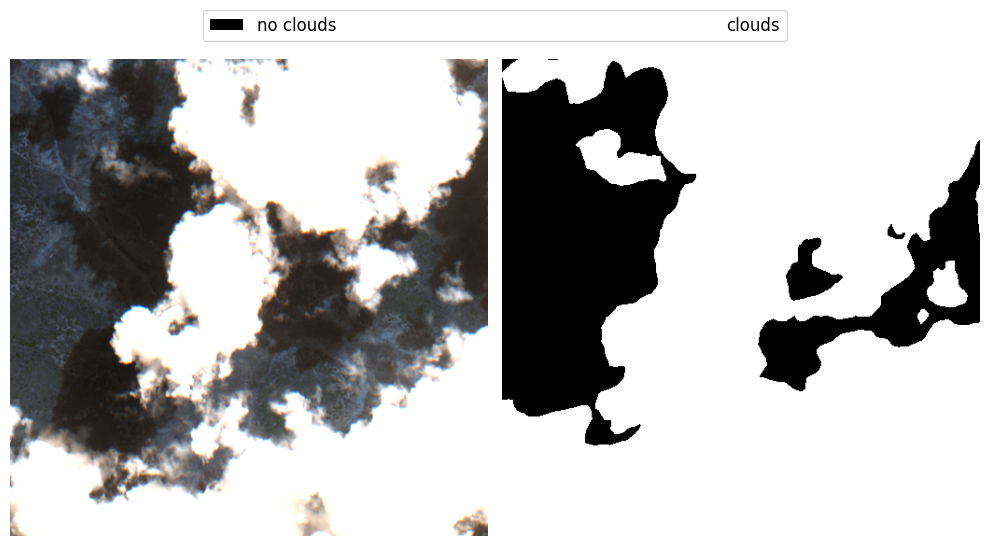

2026-03-12 08:46:13,755 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


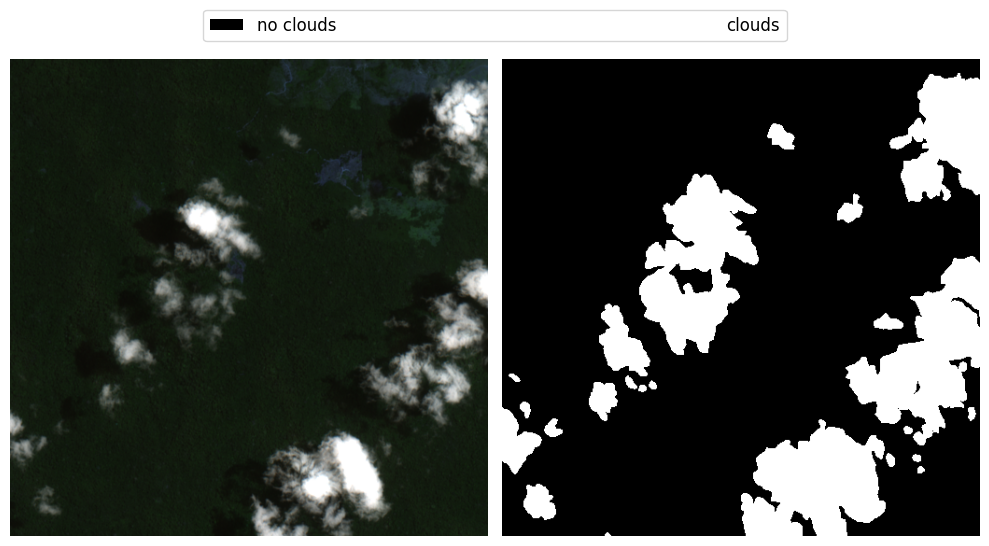

2026-03-12 08:46:14,026 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


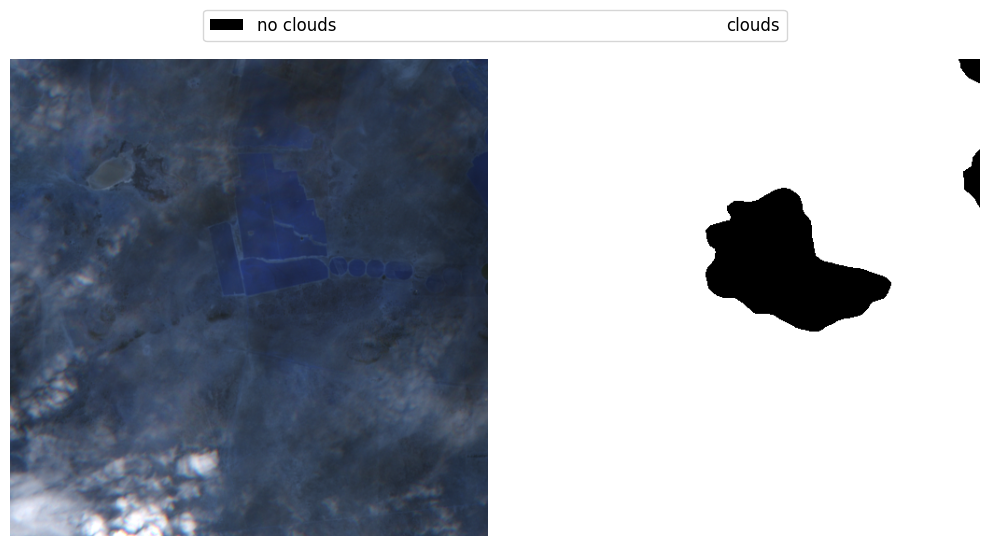

In [15]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/Sentinel-2_cloud_cover_segmentation/train/"
}
dataset = Sentinel2CloudCoverSegmentationDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(350);
dataset.show_image(1500);

In [21]:
dataset.data_distribution_table()

,Number of pixels
no clouds,9.502920e+08
clouds,1.539290e+09


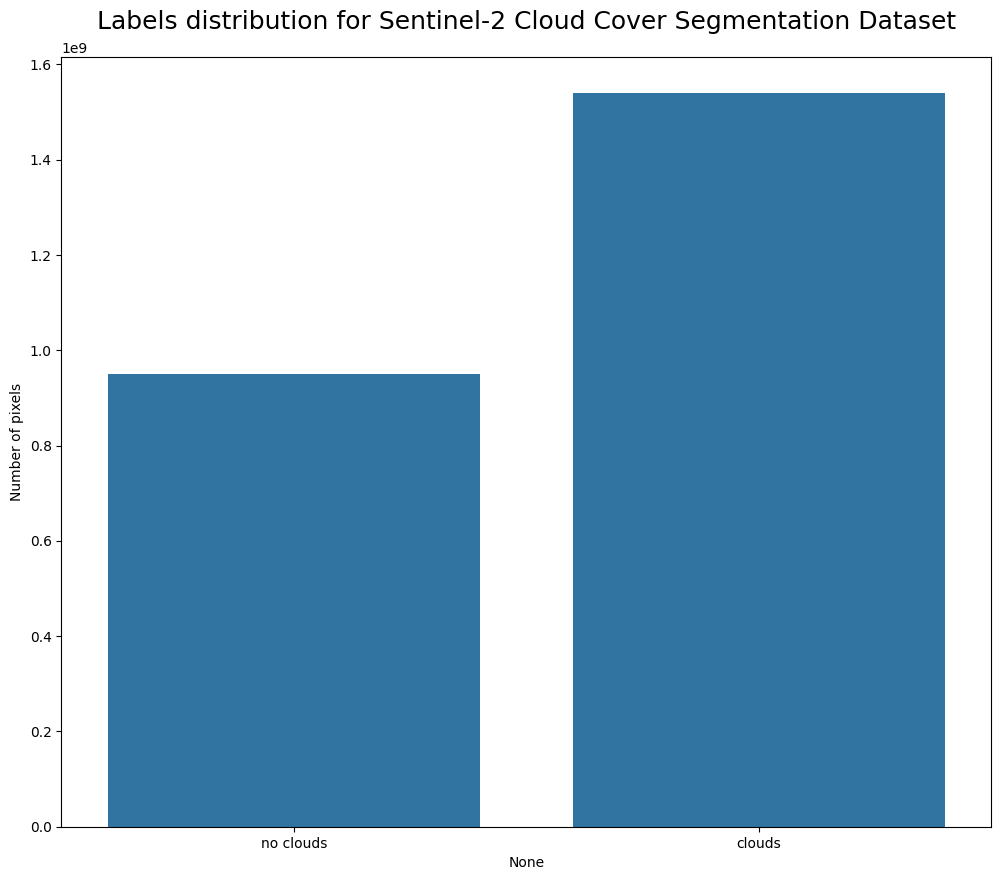

In [22]:
dataset.data_distribution_barchart();

## Load training data

In [36]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/Sentinel-2_cloud_cover_segmentation/train/",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = Sentinel2CloudCoverSegmentationDataset(train_dataset_config)
len(train_dataset)

9497

## Create the model

In [37]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/experiments/Sentinel-2_cloud_cover_segmentation"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [38]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-11-20 12:38:20,807 INFO Starting training.
training: 100%|██████████| 594/594 [01:32<00:00,  6.42it/s]
2025-11-20 12:39:53,408 INFO epoch: 1, time: 93, loss:  0.25804
testing on train set: 100%|██████████| 594/594 [00:31<00:00, 18.65it/s]
2025-11-20 12:40:27,059 INFO IOU:0.645727090227073, IOU mean:0.6374332494516379, IOU per Class:[0.59536376 0.67950273]
training: 100%|██████████| 594/594 [01:33<00:00,  6.33it/s]
2025-11-20 12:42:00,964 INFO epoch: 2, time: 93, loss:  0.22435
testing on train set: 100%|██████████| 594/594 [00:32<00:00, 18.27it/s]
2025-11-20 12:42:33,488 INFO IOU:0.6406770110567529, IOU mean:0.6337472959876642, IOU per Class:[0.5907588  0.67673579]
training: 100%|██████████| 594/594 [01:34<00:00,  6.27it/s]
2025-11-20 12:44:08,157 INFO epoch: 3, time: 95, loss:  0.21578
testing on train set: 100%|██████████| 594/594 [00:32<00:00, 18.03it/s]
2025-11-20 12:44:41,110 INFO IOU:0.6518728608693143, IOU mean:0.643639012492101, IOU per Class:[0.60347147 0.68380656]
traini

## Evaluate the model

In [40]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/Sentinel-2_cloud_cover_segmentation/test/",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = Sentinel2CloudCoverSegmentationDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/experiments/Sentinel-2_cloud_cover_segmentation/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

10980


2025-11-20 13:03:29,956 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/Sentinel-2_cloud_cover_segmentation/checkpoint.pth.tar
2025-11-20 13:03:30,439 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/Sentinel-2_cloud_cover_segmentation/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 2745/2745 [00:47<00:00, 57.24it/s]


[{'IOU': 0.6183421316872081,
  'IOU mean': 0.6114950792988186,
  'IOU per Class': array([0.57713015, 0.64586001])}]

## Predictions

2025-11-20 13:05:11,417 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/Sentinel-2_cloud_cover_segmentation/checkpoint.pth.tar
2025-11-20 13:05:11,897 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/Sentinel-2_cloud_cover_segmentation/checkpoint.pth.tar at epoch 11
2025-11-20 13:05:11,946 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2025-11-20 13:05:12,050 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


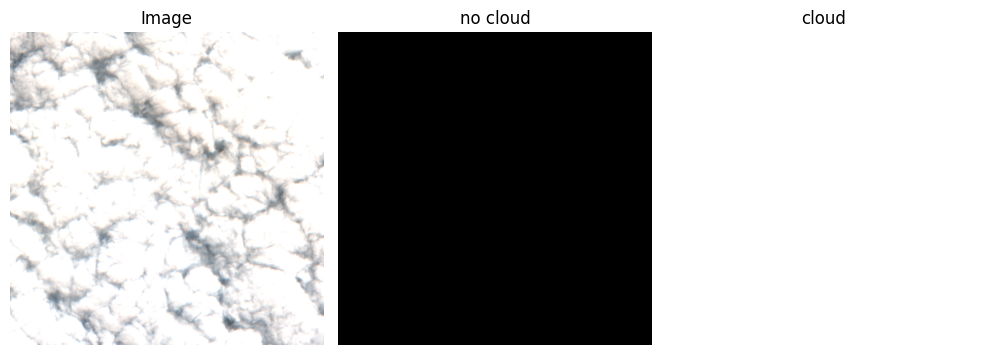

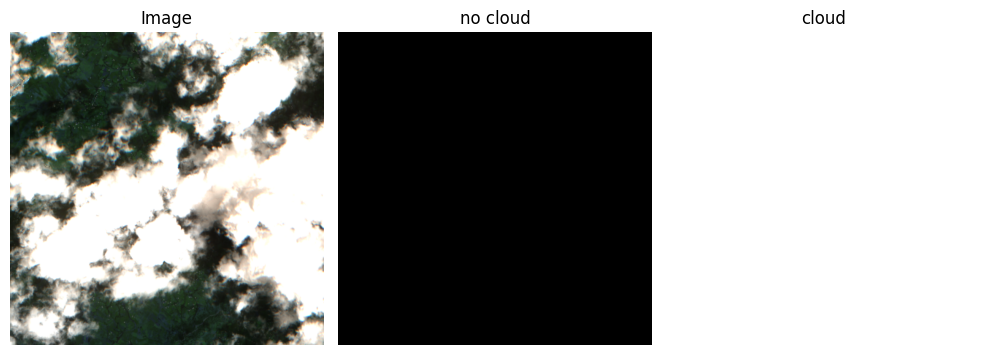

In [42]:
model_path = "/home/dragik/data/FAIR_EO/experiments/Sentinel-2_cloud_cover_segmentation/checkpoint.pth.tar"
labels = ["no cloud","cloud"]
transform = MinMaxNormTranspose()
model.load_model(model_path)

imageB02 = image_loader('/home/dragik/data/FAIR_EO/Sentinel-2_cloud_cover_segmentation/test/features/aabd/B02.tif')
imageB03 = image_loader('/home/dragik/data/FAIR_EO/Sentinel-2_cloud_cover_segmentation/test/features/aabd/B03.tif')
imageB04 = image_loader('/home/dragik/data/FAIR_EO/Sentinel-2_cloud_cover_segmentation/test/features/aabd/B04.tif')
image = np.dstack((imageB02,imageB03,imageB04))/5000
fig = model.predict_masks(image, labels, transform)

imageB02 = image_loader('/home/dragik/data/FAIR_EO/Sentinel-2_cloud_cover_segmentation/test/features/lgwg/B02.tif')
imageB03 = image_loader('/home/dragik/data/FAIR_EO/Sentinel-2_cloud_cover_segmentation/test/features/lgwg/B03.tif')
imageB04 = image_loader('/home/dragik/data/FAIR_EO/Sentinel-2_cloud_cover_segmentation/test/features/lgwg/B04.tif')
image = np.dstack((imageB02,imageB03,imageB04))/5000
fig = model.predict_masks(image, labels, transform)